In [2]:
import seaborn as sns

In [3]:
#load the taxis dataset

df = sns.load_dataset("taxis")

In [4]:
df.shape

(6433, 14)

In [5]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [6]:
# Handling missing values: checking for missing values

df.isnull().sum()


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
# identify column with missing data

missing_values=df.isnull().sum()
missing_values[missing_values>0]

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [8]:
df.tail()




,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn
6432,2019-03-13 19:31:22,2019-03-13 19:48:02,1,3.85,15.0,3.36,0.0,20.16,green,credit card,Boerum Hill,Windsor Terrace,Brooklyn,Brooklyn


In [9]:
# Impute missing values using mode. I handled missing values in the categorical columns using mode imputation.
# This preserved the dataset's rows and avoided unnecessary data loss.

cols = ['payment', 'pickup_zone','dropoff_zone','pickup_borough','dropoff_borough']
for column in cols:
    df[column]=df[column].fillna(df[column].mode()[0])



In [10]:
df[cols].isnull().sum()

payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [11]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

# Remove rows with missing values

After imputing the missing values using mode, I checked the dataset again.
All column has zero missing values.
Therefore, no rows needed to be removed due to missing values.

In [12]:
# Visualizations using Matplotlib/Pandas Plot

import pandas as pd
import matplotlib.pyplot as plt


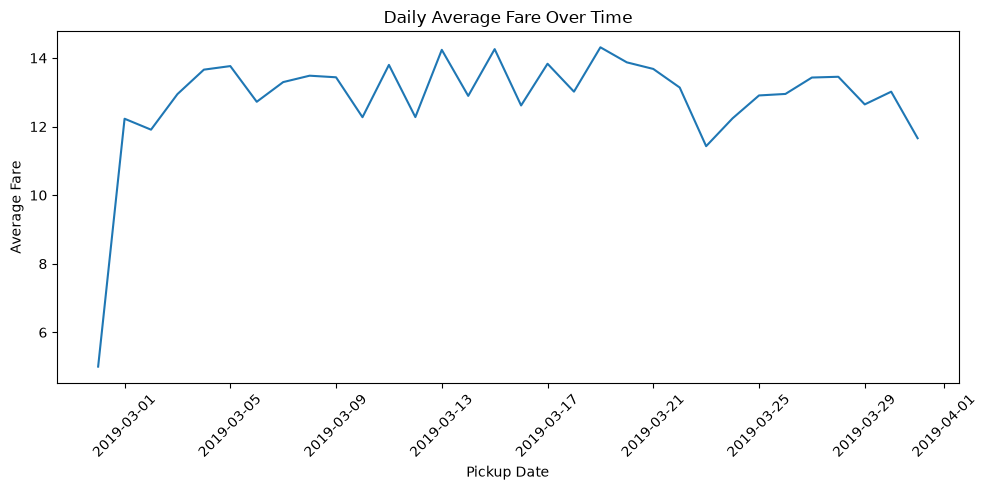

In [14]:
df['pickup'] = pd.to_datetime(df['pickup'])

df['pickup_date'] = df['pickup'].dt.date

daily_fare = df.groupby('pickup_date')['fare'].mean()

plt.figure(figsize=(10, 5))
plt.plot(daily_fare.index, daily_fare.values)

plt.xlabel('Pickup Date')
plt.ylabel('Average Fare')
plt.title('Daily Average Fare Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


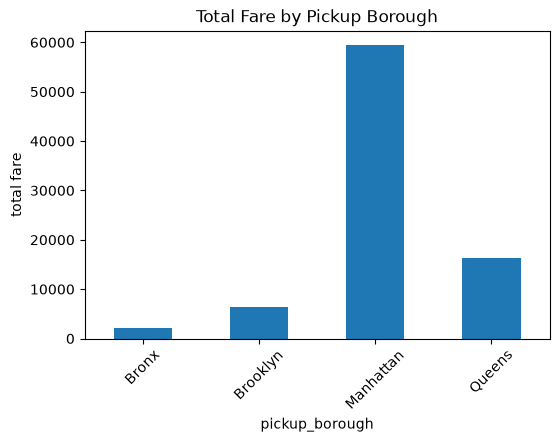

In [15]:
#Barchart

borough_fare=df.groupby('pickup_borough')['fare'].sum()

plt.figure(figsize=(6,4))
borough_fare.plot(kind='bar')
plt.title('Total Fare by Pickup Borough')
plt.xlabel('pickup_borough')
plt.ylabel('total fare')
plt.xticks(rotation=45)
plt.show()


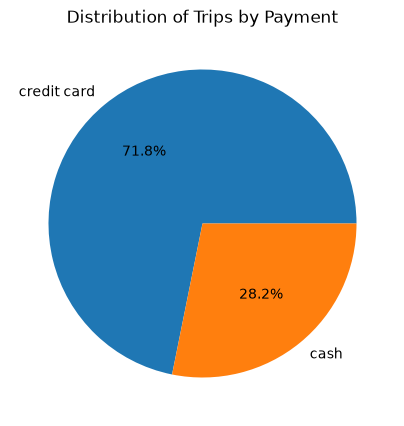

In [16]:
#PieChart

payment_counts=df['payment'].value_counts()

plt.figure(figsize=(5,5))
plt.pie(payment_counts,labels=payment_counts.index,autopct='%1.1f%%')

plt.title('Distribution of Trips by Payment')
plt.show()

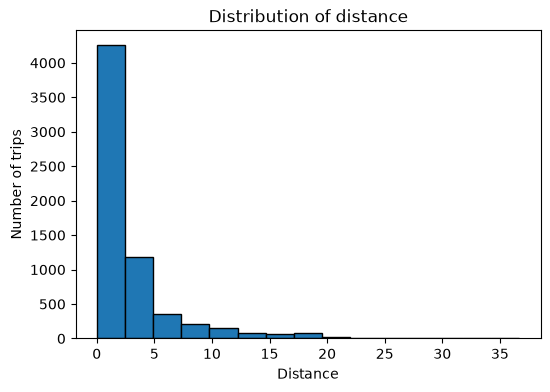

In [17]:
#Histogram

plt.figure(figsize=(6,4))
plt.hist(df['distance'],bins=15,edgecolor='black')
plt.title('Distribution of distance')
plt.xlabel('Distance')
plt.ylabel('Number of trips')
plt.show()

<Figure size 800x500 with 0 Axes>

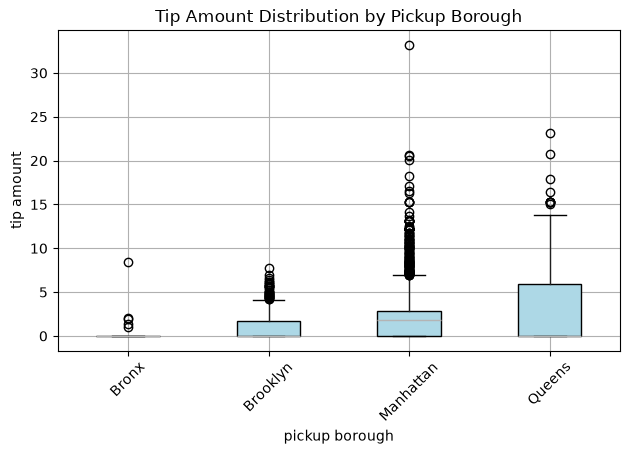

In [18]:
#Boxplot

plt.figure(figsize=(8, 5))
df.boxplot(column='tip', by='pickup_borough', patch_artist=True,
    boxprops=dict(facecolor='lightblue'))

plt.title('Tip Amount Distribution by Pickup Borough')
plt.xlabel('pickup borough')
plt.ylabel('tip amount')
plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

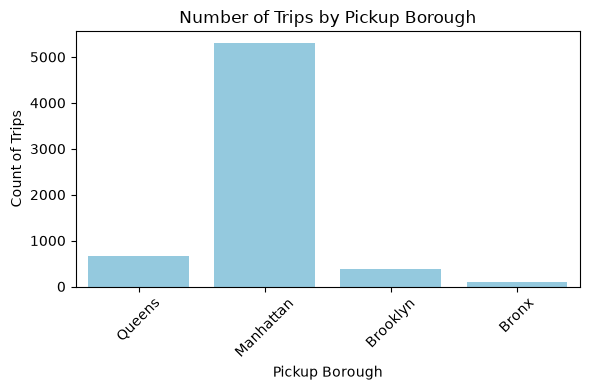

In [19]:
#countplot

plt.figure(figsize=(6, 4))

sns.countplot(x='pickup_borough', data=df,color='skyblue')

plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Count of Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
    
    

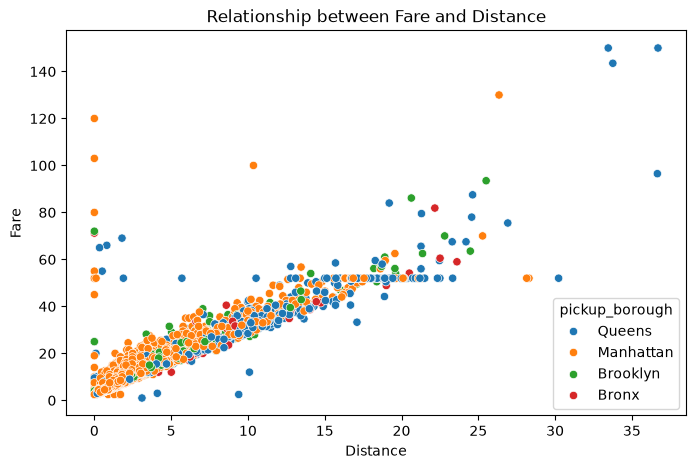

In [20]:
#scatterplot

plt.figure(figsize=(8, 5))
sns.scatterplot(x='distance',y='fare',hue='pickup_borough',data=df)
plt.title('Relationship between Fare and Distance')

plt.xlabel('Distance')
plt.ylabel('Fare')

plt.show()


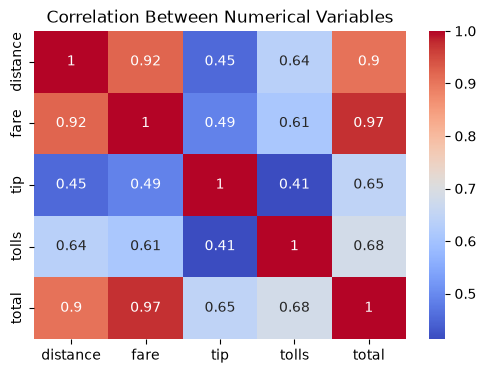

In [21]:
#Heatmap

plt.figure(figsize=(6, 4))
columns=['distance','fare','tip','tolls','total']
corr_matrix=df[columns].corr()

sns.heatmap(corr_matrix,annot=True,cmap='coolwarm')

plt.title('Correlation Between Numerical Variables')
plt.show()

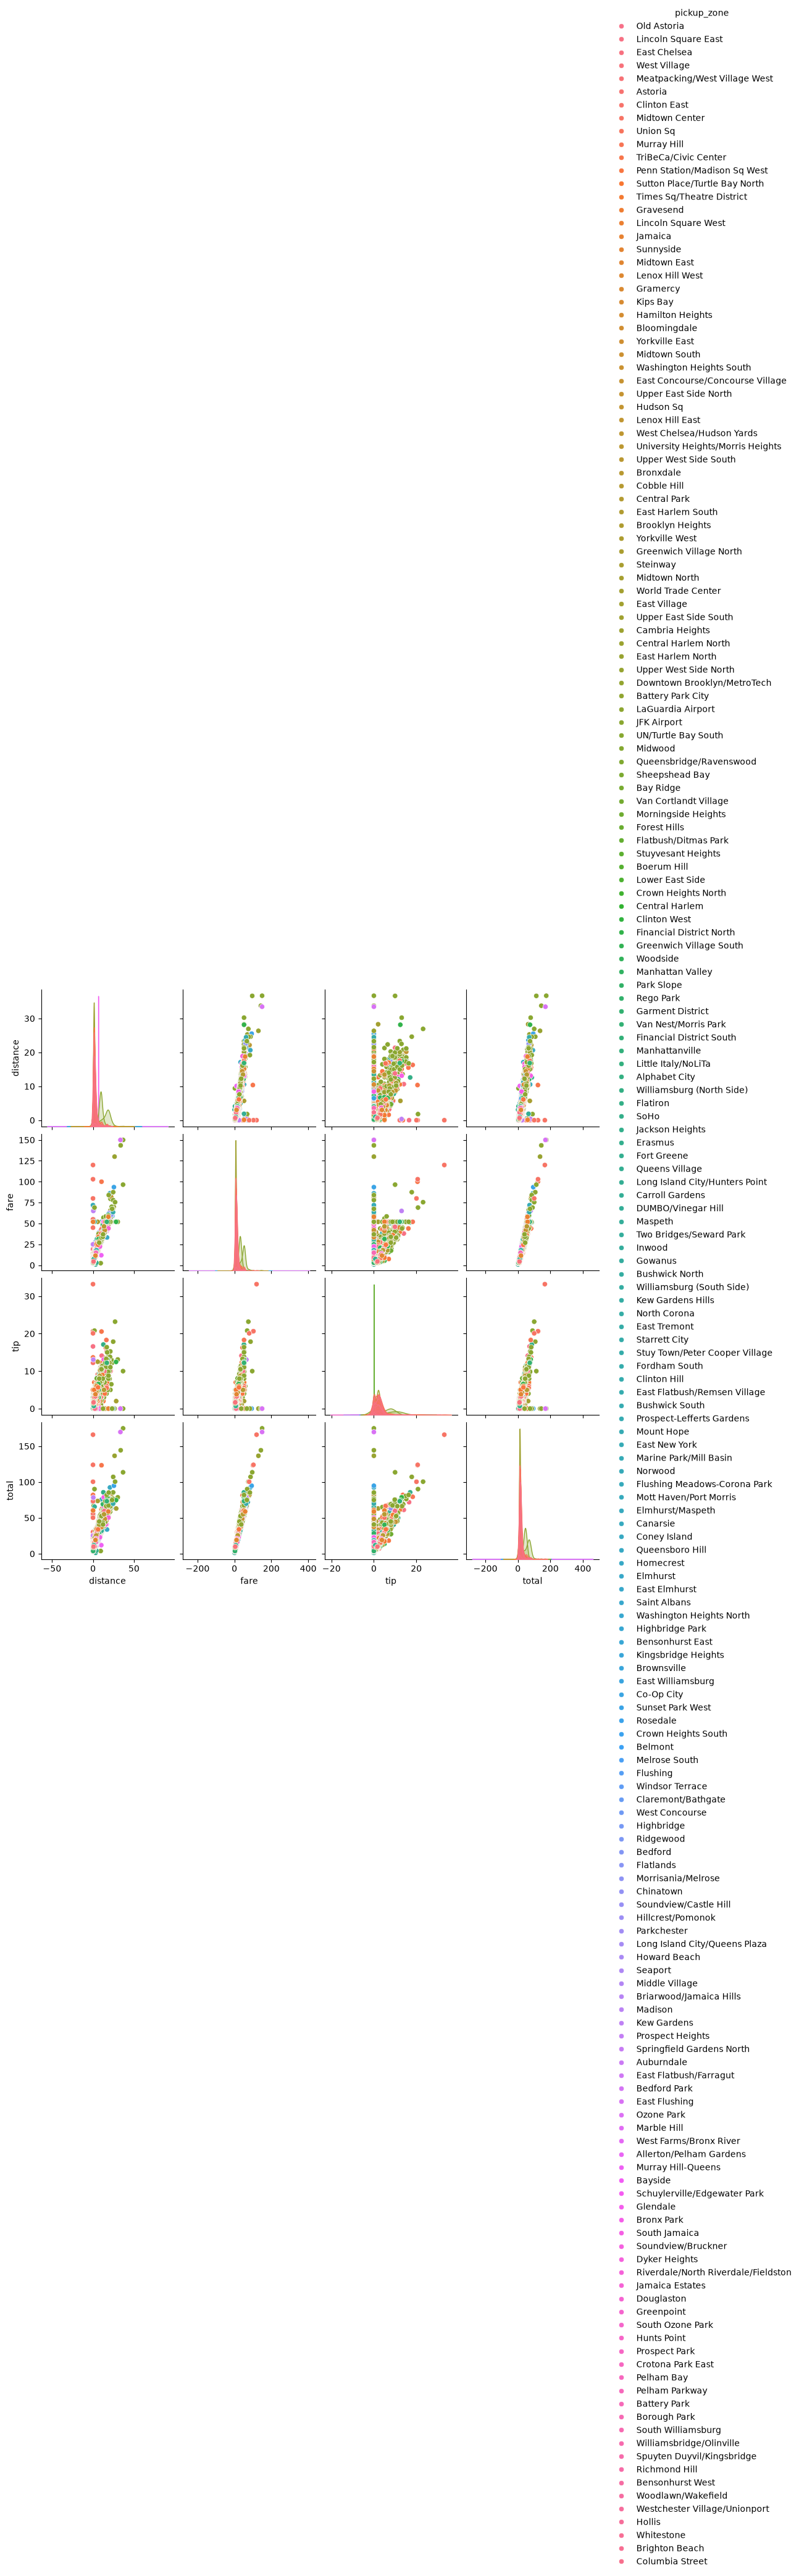

In [22]:
#Pairplot

sns.pairplot(df,vars=['distance', 'fare', 'tip', 'total'], hue='pickup_zone')
plt.show()

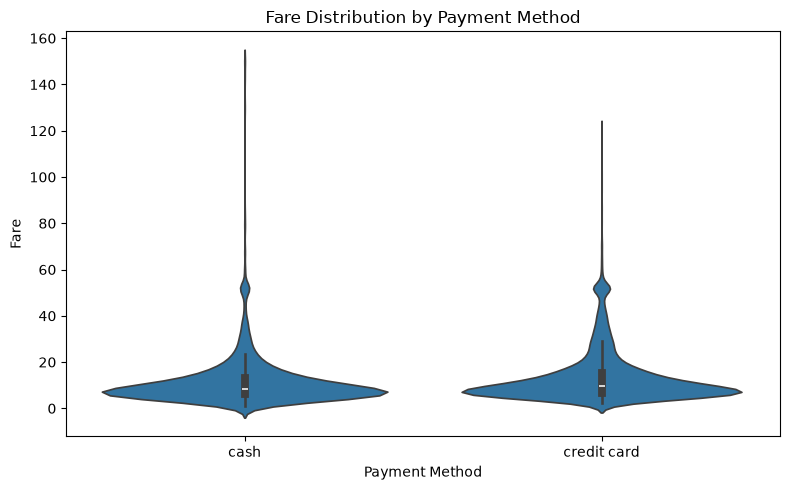

In [23]:
#Violinplot

plt.figure(figsize=(8, 5))

sns.violinplot(x='payment', y='fare', data=df)

plt.title('Fare Distribution by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.tight_layout()
plt.show()